# Phase 1: Hand Detection using YOLOv8

## Install Dependencies

In [ ]:
!pip install -U ultralytics roboflow

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 57.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 91.8/91.8 kB 10.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 66.8/66.8 kB 7.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.9/49.9 MB 19.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 40.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.5/5.5 MB 75.6 MB/s eta 0:00:00
  Attempting uninstall: opencv-python-headless
    Found existing installation: opencv-python-headless 4.13.0.90
    Uninstalling opencv-python-headless-4.13.0.90:
      Successfully uninstalled opencv-python-headless-4.13.0.90
  Attempting uninstall: idna
    Found existing installation: idna 3.11
    Uninstalling idna-3.11:
      Successfully uninstalled idna-3.11


## Create Project Folder in Drive

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

DRIVE_PROJECT_DIR = "/content/drive/MyDrive/FYP_YOLO_Hand_Detection"
os.makedirs(DRIVE_PROJECT_DIR, exist_ok=True)

print("Drive project folder ready:", DRIVE_PROJECT_DIR)

Drive project folder ready: /content/drive/MyDrive/FYP_YOLO_Hand_Detection


## Download Dataset from Roboflow (API)

In [ ]:
from roboflow import Roboflow
rf = Roboflow(api_key="enter-your-key-here")
project = rf.workspace("objectdetection-3awm0").project("hand_sign_language")
version = project.version(1)
dataset = version.download("yolov8")

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to hand_sign_language-1 in yolov8:: 100%|██████████| 1679/1679 [00:00<00:00, 2797.78it/s]


Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


## Verify Dataset Structure

In [ ]:
!ls hand_sign_language-1

data.yaml  README.roboflow.txt	test  train  valid


## Load YOLOv8 Model

In [ ]:
from ultralytics import YOLO

model = YOLO("yolov8n.pt")

## Train YOLOv8 - 50 epochs

In [ ]:
model.train(
    data="hand_sign_language-1/data.yaml",
    epochs=50,
    imgsz=640,
    batch=16,
    project="yolo_hand_detection",
    name="phase1_hand_detector"
)

Ultralytics 8.4.13 🚀 Python-3.12.12 torch-2.9.0+cu126 CUDA:0 (Tesla T4, 15095MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=hand_sign_language-1/data.yaml, degrees=0.0, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=phase1_hand_detector, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, overlap_mask=True, patience=1

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7b125ae66300>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.048048, 

## Evaluate Model

In [ ]:
model.val(
    data="hand_sign_language-1/data.yaml",
    split="test"
)

Ultralytics 8.4.13 🚀 Python-3.12.12 torch-2.9.0+cu126 CUDA:0 (Tesla T4, 15095MiB)
Model summary (fused): 73 layers, 3,005,843 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 757.5±143.3 MB/s, size: 23.0 KB)
val: Scanning /content/hand_sign_language-1/test/labels... 83 images, 5 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 83/83 2.0Kit/s 0.0s
val: New cache created: /content/hand_sign_language-1/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 6/6 2.0it/s 3.0s
                   all         83        132      0.989      0.955      0.986      0.875
Speed: 8.4ms preprocess, 7.5ms inference, 0.0ms loss, 3.0ms postprocess per image
Results saved to /content/runs/detect/val


ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7b125a270110>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.048048, 

## Run Inference on Test Images

In [ ]:
model.predict(
    source="hand_sign_language-1/test/images",
    conf=0.4,
    save=True
)


image 1/83 /content/hand_sign_language-1/test/images/AudiBlock_1_mp4-0004_jpg.rf.c8c6badaf851ff457901ab8407d69210.jpg: 640x640 2 hands, 7.2ms
image 2/83 /content/hand_sign_language-1/test/images/AudiBlock_1_mp4-0008_jpg.rf.5728f760db5e2fe0ce00099c0e1c4251.jpg: 640x640 2 hands, 7.2ms
image 3/83 /content/hand_sign_language-1/test/images/AudiBlock_1_mp4-0013_jpg.rf.d38c47cf2d0f9decee5c0d4fb0bbdc10.jpg: 640x640 2 hands, 8.6ms
image 4/83 /content/hand_sign_language-1/test/images/AudiBlock_1_mp4-0015_jpg.rf.a917819ba743fa158fbe602b54e479ef.jpg: 640x640 2 hands, 7.2ms
image 5/83 /content/hand_sign_language-1/test/images/AudiBlock_1_mp4-0024_jpg.rf.27f9c6ab5462101a7a820e8ec7268c4c.jpg: 640x640 2 hands, 7.2ms
image 6/83 /content/hand_sign_language-1/test/images/AudiBlock_1_mp4-0026_jpg.rf.b52c7b5264009b6b038a1ed91ef7ff1a.jpg: 640x640 2 hands, 7.2ms
image 7/83 /content/hand_sign_language-1/test/images/AudiBlock_2_mp4-0008_jpg.rf.d64ac4f4e8b2948057c02125f384a3b9.jpg: 640x640 1 hand, 7.3ms
image 

[ultralytics.engine.results.Results object with attributes:
 
 boxes: ultralytics.engine.results.Boxes object
 keypoints: None
 masks: None
 names: {0: 'hand'}
 obb: None
 orig_img: array([[[138, 151, 153],
         [138, 151, 153],
         [138, 151, 153],
         ...,
         [248, 248, 248],
         [249, 249, 249],
         [250, 250, 250]],
 
        [[138, 151, 153],
         [138, 151, 153],
         [137, 150, 152],
         ...,
         [250, 250, 250],
         [250, 250, 250],
         [251, 251, 251]],
 
        [[137, 150, 152],
         [137, 150, 152],
         [137, 150, 152],
         ...,
         [251, 251, 251],
         [252, 252, 252],
         [253, 253, 253]],
 
        ...,
 
        [[ 63,  77,  89],
         [ 63,  77,  89],
         [ 64,  78,  90],
         ...,
         [192, 187, 188],
         [192, 187, 188],
         [192, 187, 188]],
 
        [[ 64,  78,  90],
         [ 64,  78,  90],
         [ 65,  79,  91],
         ...,
         [192, 187, 

## Save Trained Model

## Copy ALL YOLO Outputs to Drive

In [ ]:
import shutil

SRC_RUNS = "runs"
DST_RUNS = os.path.join(DRIVE_PROJECT_DIR, "runs_backup")

if os.path.exists(DST_RUNS):
    shutil.rmtree(DST_RUNS)

shutil.copytree(SRC_RUNS, DST_RUNS)

print("✅ All YOLO runs backed up to Google Drive!")

✅ All YOLO runs backed up to Google Drive!


## Copy Trained Weights Separately

In [ ]:
WEIGHTS_SRC = "runs/detect/yolo_hand_detection/phase1_hand_detector/weights"
WEIGHTS_DST = os.path.join(DRIVE_PROJECT_DIR, "weights")

os.makedirs(WEIGHTS_DST, exist_ok=True)

for file in os.listdir(WEIGHTS_SRC):
    shutil.copy(
        os.path.join(WEIGHTS_SRC, file),
        WEIGHTS_DST
    )

print("✅ Model weights saved separately!")

✅ Model weights saved separately!


## Save Dataset Metadata

In [ ]:
shutil.make_archive(
    os.path.join(DRIVE_PROJECT_DIR, "dataset_yolo"),
    'zip',
    "hand_sign_language-1"
)

print("✅ Dataset zipped and saved!")

✅ Dataset zipped and saved!


In [ ]:
!ls /content/runs/detect/yolo_hand_detection/phase1_hand_detector/weights

best.pt  last.pt


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

!mkdir -p /content/drive/MyDrive/YOLO_Phase1_HandDetector
!cp /content/runs/detect/yolo_hand_detection/phase1_hand_detector/weights/best.pt \
     /content/drive/MyDrive/YOLO_Phase1_HandDetector/

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# Phase 2: ROI Extraction (Hand Cropping)

## Mount Google Drive

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Define Drive Paths

In [ ]:
import os

# Root project folder in Drive
DRIVE_ROOT = "/content/drive/MyDrive/FYP_YOLO_Hand_Detection"

# YOLO trained model
YOLO_MODEL_PATH = f"{DRIVE_ROOT}/weights/best.pt"

# Roboflow dataset root
DATASET_ROOT = "/content/hand_sign_language-1"

# Output directories
ROI_IMAGE_ROOT = f"{DRIVE_ROOT}/roi_images_v3"
ROI_METADATA_ROOT = f"{DRIVE_ROOT}/roi_metadata_v3"

# Create base folders
os.makedirs(ROI_IMAGE_ROOT, exist_ok=True)
os.makedirs(ROI_METADATA_ROOT, exist_ok=True)

print("Paths ready")

Paths ready


## Load YOLO Model

In [ ]:
from ultralytics import YOLO

model = YOLO(YOLO_MODEL_PATH)
print("YOLO model loaded successfully")

YOLO model loaded successfully


## Cell 4: ROI Extraction Logic (CORE CELL)

This cell:  
	•	Runs YOLO on each image  
	•	Crops hand region  
	•	Skips frames with no hand detected
  •	Adds padding  
  •	Clamps crop inside image  
  •	Rejects very small ROIs  
  •	Resizes to 128×128 (gesture-friendly)  

Saves clean metadata
	•	Saves:  
	•	Cropped ROI image  
	•	Bounding box + confidence metadata  

In [ ]:
import cv2
import pandas as pd
import numpy as np
from tqdm import tqdm

def extract_roi(split):
    INPUT_IMAGES_DIR = os.path.join(DATASET_ROOT, split, "images")
    OUTPUT_IMAGE_DIR = os.path.join(ROI_IMAGE_ROOT, split)
    OUTPUT_META_DIR = os.path.join(ROI_METADATA_ROOT, split)

    os.makedirs(OUTPUT_IMAGE_DIR, exist_ok=True)
    os.makedirs(OUTPUT_META_DIR, exist_ok=True)

    metadata = []

    image_files = [f for f in os.listdir(INPUT_IMAGES_DIR) if f.endswith(".jpg")]

    for img_name in tqdm(image_files, desc=f"Processing {split}"):
        img_path = os.path.join(INPUT_IMAGES_DIR, img_name)
        image = cv2.imread(img_path)

        if image is None:
            continue

        h_img, w_img, _ = image.shape

        results = model(image, conf=0.35, verbose=False)

        if len(results[0].boxes) == 0:
            continue

        # FIX 1: choose largest bounding box
        boxes = results[0].boxes.xyxy.cpu().numpy()
        confs = results[0].boxes.conf.cpu().numpy()

        areas = (boxes[:, 2] - boxes[:, 0]) * (boxes[:, 3] - boxes[:, 1])
        best_idx = np.argmax(areas)

        x1, y1, x2, y2 = boxes[best_idx].astype(int)
        conf = float(confs[best_idx])

        # FIX 2: padding
        pad = 0.15
        bw = x2 - x1
        bh = y2 - y1

        x1 = max(0, int(x1 - pad * bw))
        y1 = max(0, int(y1 - pad * bh))
        x2 = min(w_img, int(x2 + pad * bw))
        y2 = min(h_img, int(y2 + pad * bh))

        roi = image[y1:y2, x1:x2]

        # FIX 3: minimum size filter
        if roi.size == 0 or roi.shape[0] < 80 or roi.shape[1] < 80:
            continue

        # FIX 4: resize for CNN
        roi = cv2.resize(roi, (224, 224))

        roi_filename = img_name.replace(".jpg", "_roi_v3.jpg")
        roi_path = os.path.join(OUTPUT_IMAGE_DIR, roi_filename)

        cv2.imwrite(roi_path, roi)

        metadata.append({
            "original_image": img_name,
            "roi_image": roi_filename,
            "x1": x1,
            "y1": y1,
            "x2": x2,
            "y2": y2,
            "confidence": conf
        })

    # Save metadata CSV (FIXED)
    df = pd.DataFrame(metadata)
    csv_path = os.path.join(OUTPUT_META_DIR, f"roi_metadata_{split}.csv")

    os.makedirs(os.path.dirname(csv_path), exist_ok=True)
    df.to_csv(csv_path, index=False)

    print(f"{split.upper()} → ROI images extracted: {len(df)}")
    print(f"Metadata saved to: {csv_path}")


## Run ROI Extraction for ALL SPLITS

In [ ]:
extract_roi("train")
extract_roi("valid")
extract_roi("test")

Processing train: 100%|██████████| 584/584 [00:10<00:00, 58.19it/s]


TRAIN → ROI images extracted: 294
Metadata saved to: /content/drive/MyDrive/FYP_YOLO_Hand_Detection/roi_metadata_v3/train/roi_metadata_train.csv


Processing valid: 100%|██████████| 167/167 [00:02<00:00, 57.58it/s]


VALID → ROI images extracted: 84
Metadata saved to: /content/drive/MyDrive/FYP_YOLO_Hand_Detection/roi_metadata_v3/valid/roi_metadata_valid.csv


Processing test: 100%|██████████| 83/83 [00:01<00:00, 46.47it/s]

TEST → ROI images extracted: 34
Metadata saved to: /content/drive/MyDrive/FYP_YOLO_Hand_Detection/roi_metadata_v3/test/roi_metadata_test.csv


## Quick Visual Sanity Check

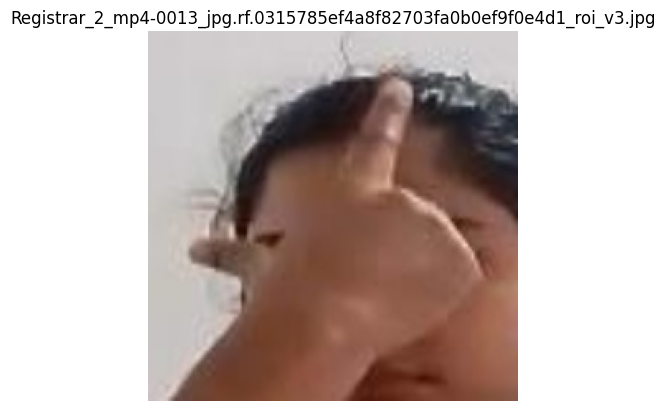

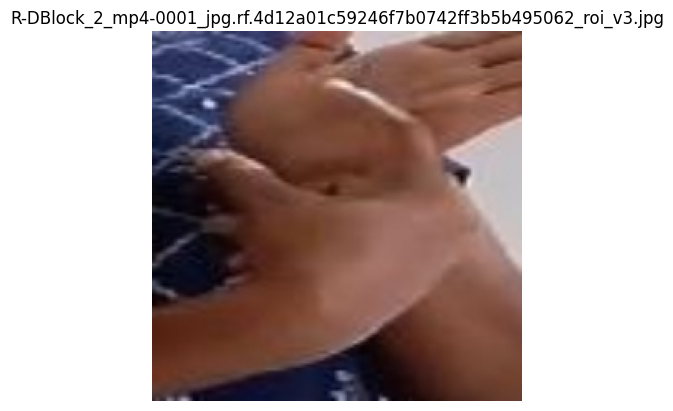

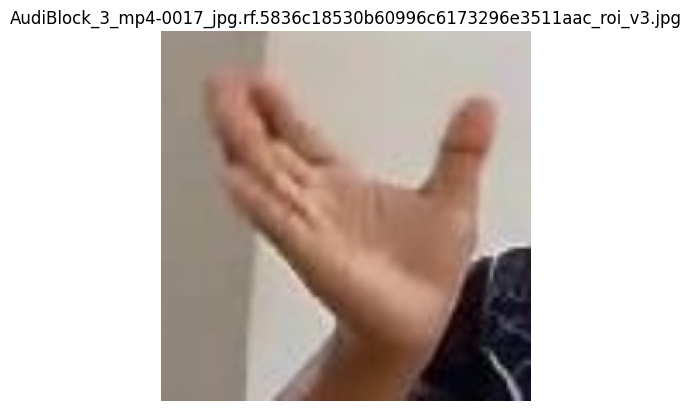

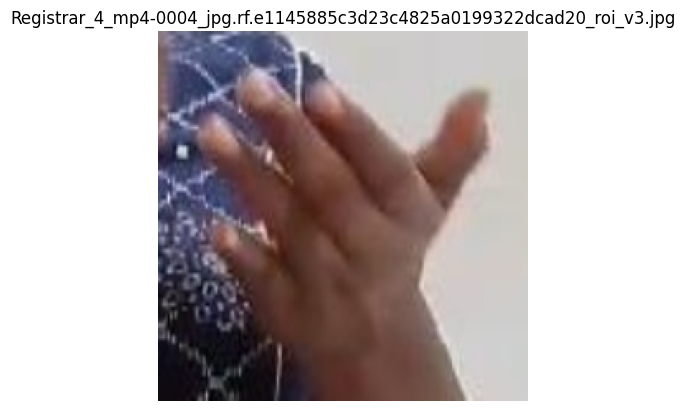

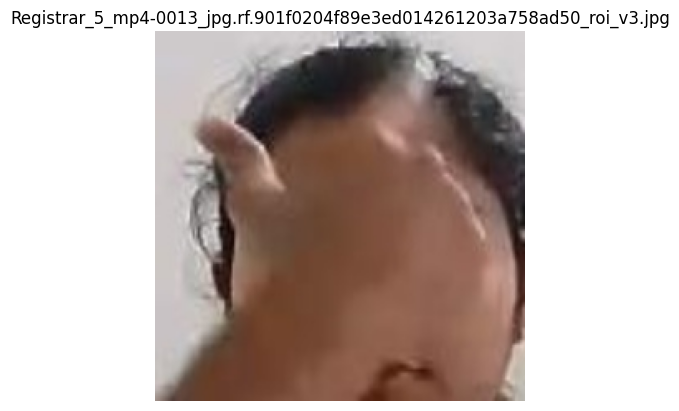

In [ ]:
import matplotlib.pyplot as plt

sample_dir = os.path.join(ROI_IMAGE_ROOT, "train")
sample_images = os.listdir(sample_dir)[:5]

for img_name in sample_images:
    img = cv2.imread(os.path.join(sample_dir, img_name))
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    plt.imshow(img)
    plt.axis("off")
    plt.title(img_name)
    plt.show()


# IMAGE + METADATA REORGANISATION (SAFE, IN-PLACE)

## Imports & paths

In [ ]:
import os
import shutil
import pandas as pd
from tqdm import tqdm

DRIVE_ROOT = "/content/drive/MyDrive/FYP_YOLO_Hand_Detection"

ROI_IMAGE_ROOT = f"{DRIVE_ROOT}/roi_images_v3"
ROI_METADATA_ROOT = f"{DRIVE_ROOT}/roi_metadata_v3"

splits = ["train", "valid", "test"]

## Function to reorganise images + update metadata

In [ ]:
def reorganize_split(split):
    print(f"\nProcessing {split.upper()}")

    img_dir = os.path.join(ROI_IMAGE_ROOT, split)
    meta_csv = os.path.join(
        ROI_METADATA_ROOT, split, f"roi_metadata_{split}.csv"
    )

    df = pd.read_csv(meta_csv)

    class_names = []

    for idx, row in tqdm(df.iterrows(), total=len(df)):
        roi_img = row["roi_image"]
        class_name = roi_img.split("_")[0]
        class_names.append(class_name)

        class_dir = os.path.join(img_dir, class_name)
        os.makedirs(class_dir, exist_ok=True)

        src = os.path.join(img_dir, roi_img)
        dst = os.path.join(class_dir, roi_img)

        if os.path.exists(src):
            shutil.move(src, dst)

    # add class column
    df["class_name"] = class_names

    # save updated metadata
    new_csv = os.path.join(
        ROI_METADATA_ROOT,
        split,
        f"roi_metadata_{split}_with_labels.csv"
    )
    df.to_csv(new_csv, index=False)

    print(f"✔ {split}: images reorganised")
    print(f"✔ Metadata saved: {new_csv}")

## Run for train / valid / test

In [ ]:
for split in splits:
    reorganize_split(split)


Processing TRAIN


100%|██████████| 294/294 [00:00<00:00, 294.90it/s]


✔ train: images reorganised
✔ Metadata saved: /content/drive/MyDrive/FYP_YOLO_Hand_Detection/roi_metadata_v3/train/roi_metadata_train_with_labels.csv

Processing VALID


100%|██████████| 84/84 [00:00<00:00, 258.73it/s]


✔ valid: images reorganised
✔ Metadata saved: /content/drive/MyDrive/FYP_YOLO_Hand_Detection/roi_metadata_v3/valid/roi_metadata_valid_with_labels.csv

Processing TEST


100%|██████████| 34/34 [00:00<00:00, 223.74it/s]

✔ test: images reorganised
✔ Metadata saved: /content/drive/MyDrive/FYP_YOLO_Hand_Detection/roi_metadata_v3/test/roi_metadata_test_with_labels.csv
